# Gráficos para el póster

Compara todos los modelos de una corrida del pipeline (`models/<día>__<hora>/`) y guarda cada
gráfico en PNG y PDF (vectorial, para el póster) en `<corrida>/poster/`.

- Las corridas nuevas guardan sus métricas en `metrics.json` y el notebook solo las lee.
- Una corrida vieja sin `metrics.json` se reevalúa sobre test y control con los mismos splits
  del pipeline (tarda unos minutos y queda guardado). Para eso hay que indicar con qué tamaños y
  ventana se entrenó. Las corridas viejas no tienen curvas de aprendizaje, y sus
  `classic_features` no se pueden evaluar con el código actual.

**Usar `control` para comparar**: test ya se usó para elegir la época de cada red y el modelo
ganador, así que su F1 es optimista.

In [1]:
import logging
import os
from pathlib import Path

# El notebook corre desde notebooks/: subimos hasta la raíz del repo para importar src
while not Path("pyproject.toml").exists():
    os.chdir("..")

import matplotlib.pyplot as plt
from IPython.display import display

from src.data.samples import WindowSpec
from src.poster import plots as P
from src.poster.data import latest_run, load_run

%matplotlib inline
logging.basicConfig(level=logging.WARNING)
logging.getLogger("src").setLevel(logging.INFO)

/home/sebastian/personal/uba/Aprendizaje-Automatico-UBA/tp/TP2-Aprendizaje-Automatico-UBA/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuración

In [2]:
# Corrida a graficar: por defecto la más reciente de models/.
# Para otra: RUN_DIR = Path("models/<día>__<hora>")
RUN_DIR = latest_run()
print("Corrida:", RUN_DIR)

# Split con el que se comparan los modelos: "control" (recomendado) o "test"
SPLIT = "control"

# Solo si la corrida no tiene metrics.json: con qué datos se entrenó (los splits dependen de esto).
# Son los argumentos del pipeline; por defecto, los de src/constants.py
OLD_RUN = dict(capitalization_size=1000, punctuation_size=1000, window=WindowSpec())

OUT_DIR = RUN_DIR / "poster"


def show_and_save(fig, name: str) -> None:
    """Muestra el gráfico y lo guarda en OUT_DIR como PNG y PDF"""
    if fig is None:
        print(f"{name}: esta corrida no tiene los modelos o datos para este gráfico")
        return
    P.save_figure(fig, OUT_DIR, name)
    display(fig)
    plt.close(fig)

Corrida: models/2026-11-16__13-37-08


In [3]:
report = load_run(RUN_DIR, **OLD_RUN)
print("Configuración:", report["config"])
print()
print(P.f1_table(report, SPLIT))

Configuración: {'capitalization_size': 5000, 'punctuation_size': 5000, 'experiments': None, 'window': {'min_size': 5, 'max_size': 60, 'distribution': 'uniform'}, 'n_epochs': 15, 'learning_rate': 0.001, 'grad_clip_norm': 1.0, 'class_weight_power': 0.5, 'batch_size': 200, 'hidden_dim': 128, 'random_seed': 12}

modelo                            Capitalización  Puntuación inicial    Puntuación final  promedio
RF atributos                               0.395               0.723               0.344     0.487
RF atributos + diccionario                 0.634               0.744               0.377     0.585
RF embeddings                              0.565               0.651               0.379     0.532
RNN                                        0.482               0.709               0.455     0.549
BiRNN                                      0.530               0.753               0.549     0.611
RNN conjunta                               0.521               0.706               0.454     0.5

## 1. Comparación general

F1 macro de cada modelo en cada tarea (es la métrica del enunciado).

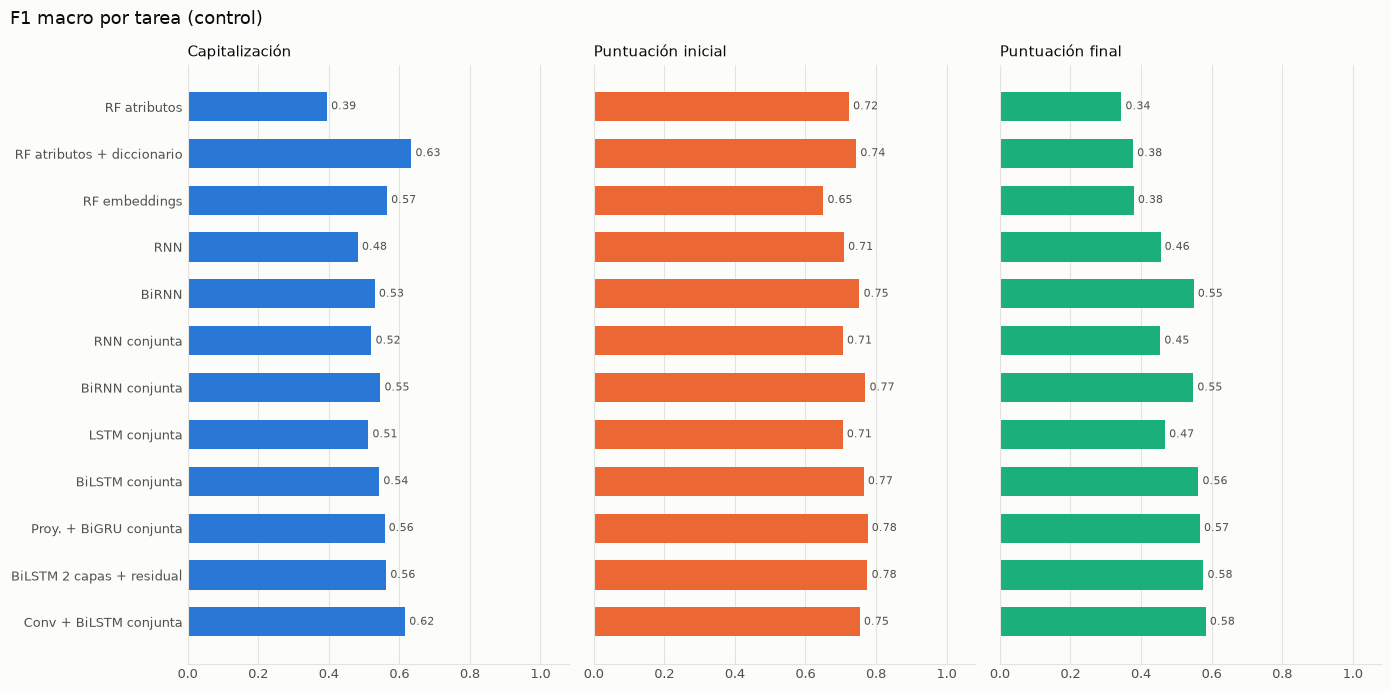

In [4]:
show_and_save(P.plot_f1_by_task(report, SPLIT), "1_f1_por_tarea")

## 2. ¿Qué clase le costó más a qué modelo?

F1 de cada clase, a nivel palabra. Las clases raras (`¿`, `?`, MiXta, MAYÚS) suelen ser las
más difíciles.

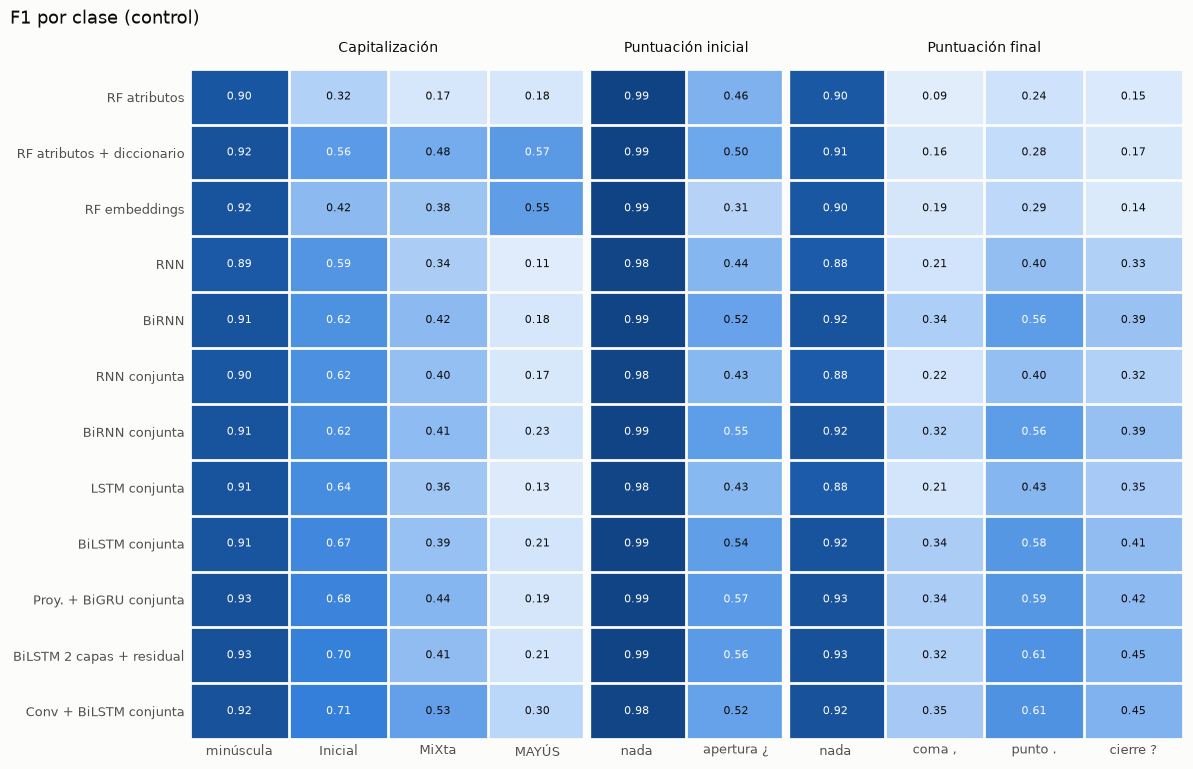

In [5]:
show_and_save(P.plot_class_f1(report, SPLIT), "2_f1_por_clase")

## 3. ¿Conviene compartir pesos entre tareas?

Cada red entrenada solo con su problema contra la misma arquitectura conjunta, que aprende
capitalización y puntuación a la vez con una sola capa recurrente y una cabeza por tarea.

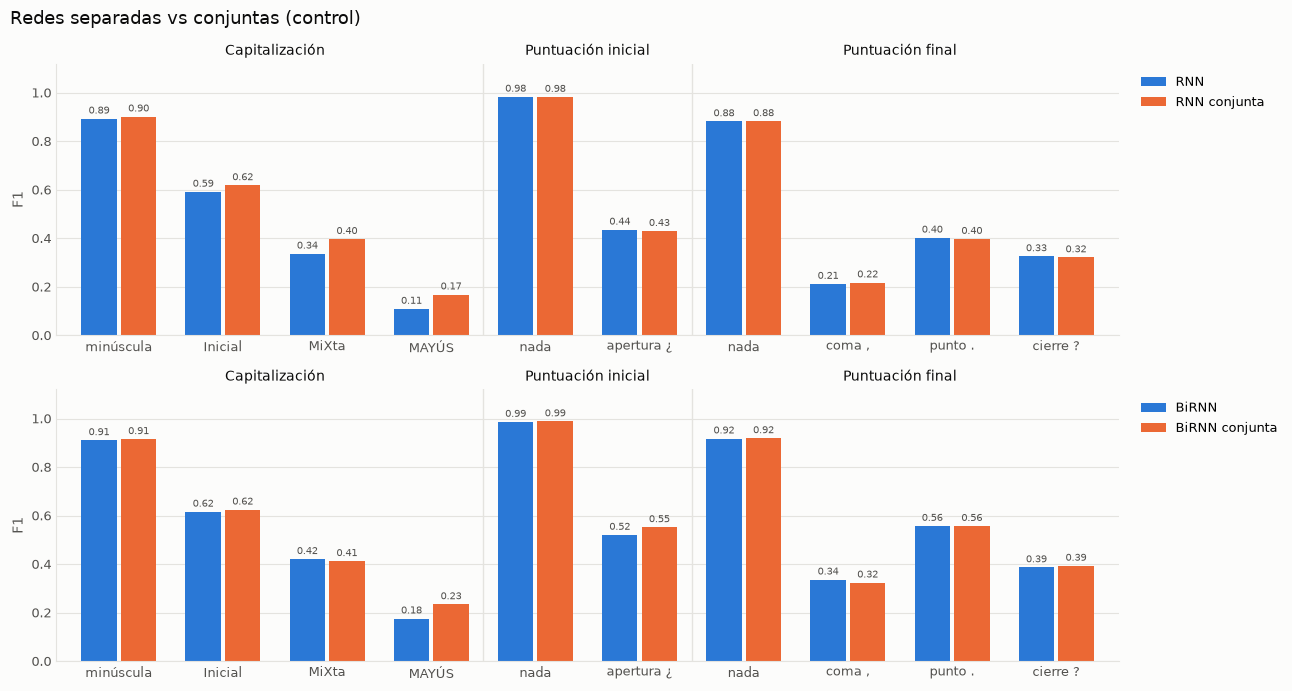

In [6]:
shared_weights = [("standard_rnn", "joint_rnn"), ("bidirectional_rnn", "bidirectional_joint_rnn")]
show_and_save(P.plot_pairs_by_class(report, SPLIT, shared_weights, "Redes separadas vs conjuntas"),
              "3_compartir_pesos")

## 4. ¿Cómo se relaciona con la arquitectura? Unidireccional vs bidireccional

Una red unidireccional, al leer la primera palabra de una pregunta, todavía no vio el final:
no puede saber si va `¿`. La bidireccional también lee de derecha a izquierda.

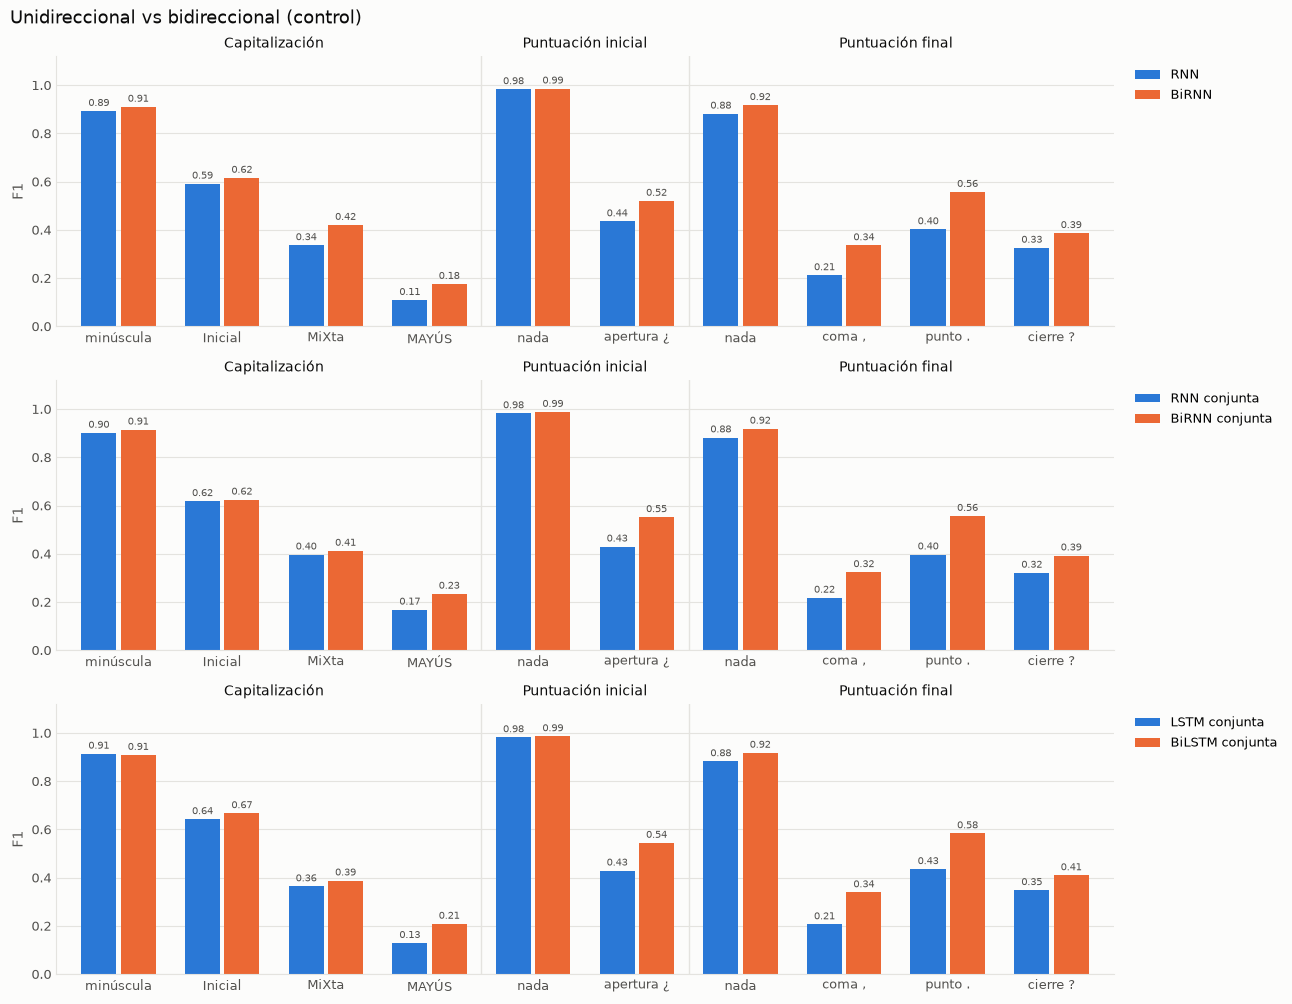

In [7]:
directions = [("standard_rnn", "bidirectional_rnn"), ("joint_rnn", "bidirectional_joint_rnn"),
              ("joint_lstm", "bidirectional_joint_lstm")]
show_and_save(P.plot_pairs_by_class(report, SPLIT, directions, "Unidireccional vs bidireccional"),
              "4_unidireccional_vs_bidireccional")

## 5. Curvas de aprendizaje

F1 macro promedio en test por época de cada red, sobre las tareas del problema; el punto grande
es la época con la que se quedó. En las redes conjuntas esa época se eligió con el promedio de
las 3 tareas, así que puede no ser el máximo de esta curva. Solo para corridas con historial
(las del pipeline actual).

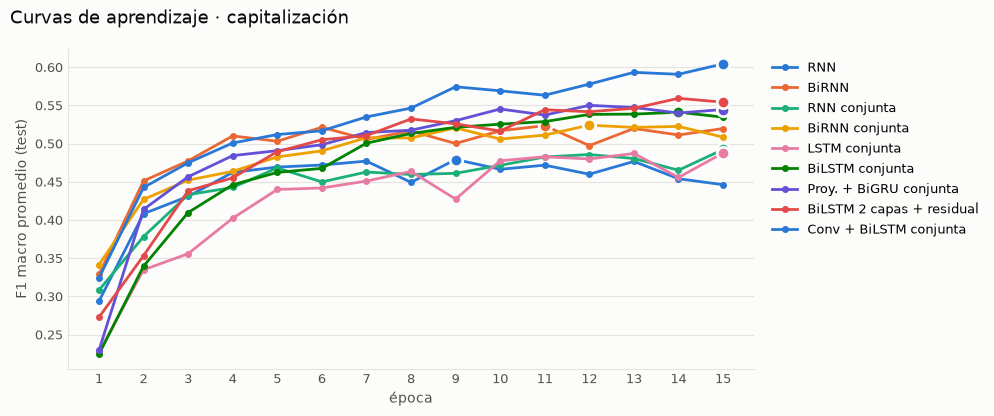

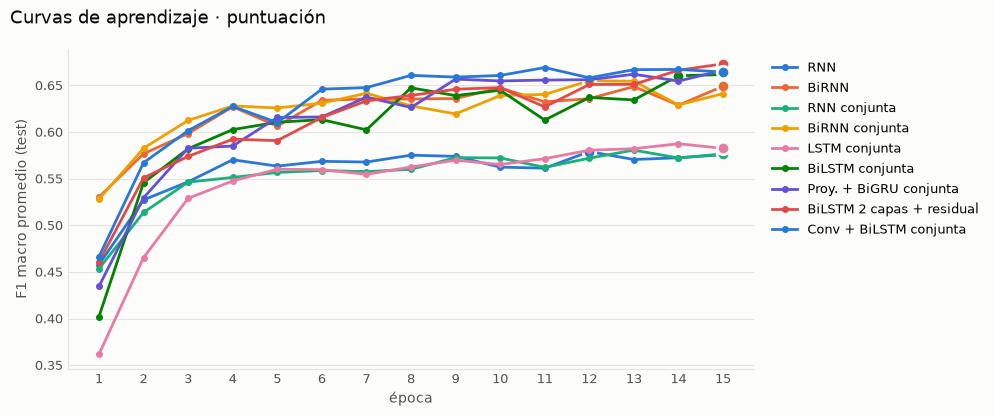

In [8]:
for problem in report["problems"]:
    show_and_save(P.plot_learning_curves(report, problem), f"5_curvas_{problem}")

## 6. Matrices de confusión del mejor modelo de cada problema

Normalizadas por fila: cada fila muestra a dónde fueron las palabras de esa clase real (la
diagonal es el recall).

Mejor modelo por problema: {'CapitalizationProblem': 'classic_features_dictionary', 'PunctuationProblem': 'joint_residual_stacked_bilstm'}


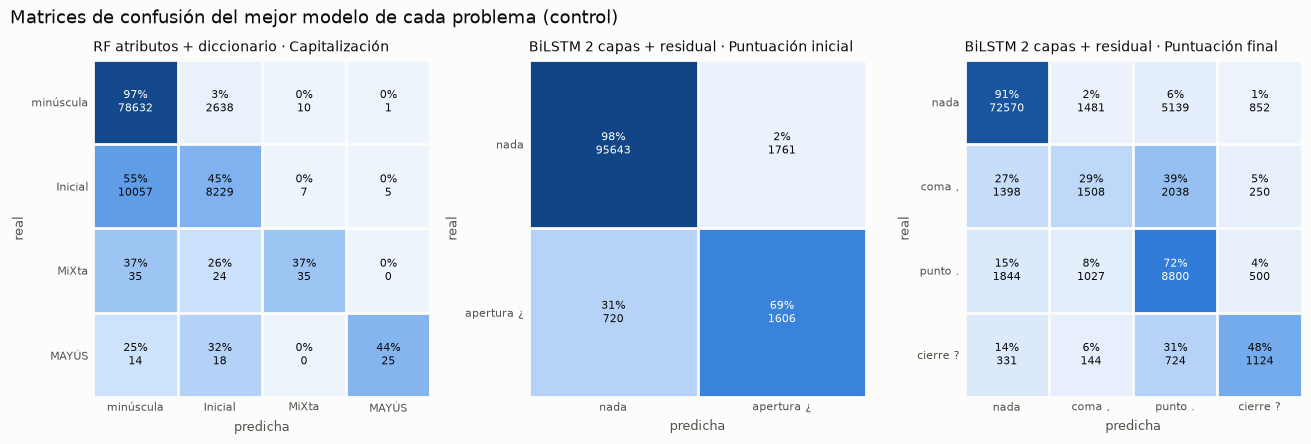

In [9]:
best = {problem: P.best_model(report, problem, SPLIT) for problem in report["problems"]}
print("Mejor modelo por problema:", best)
show_and_save(P.plot_confusions(report, SPLIT, best), "6_confusion_mejores")

## 7. ¿Mejoran las arquitecturas nuevas?

La mejor red conjunta de antes (`bidirectional_joint_lstm`) contra las 3 variantes de
`src/joint_networks.py`, que cambian una idea cada una:

- **Proyección + BiGRU**: procesa cada token solo (lineal + GELU) antes de leer la oración, con
  una GRU y cabezas MLP.
- **BiLSTM de 2 capas + residual**: dos capas recurrentes, y las cabezas reciben también el
  token proyectado.
- **Conv + BiLSTM**: una convolución junta cada token con sus vecinos (las piezas de la misma
  palabra) antes de la BiLSTM.

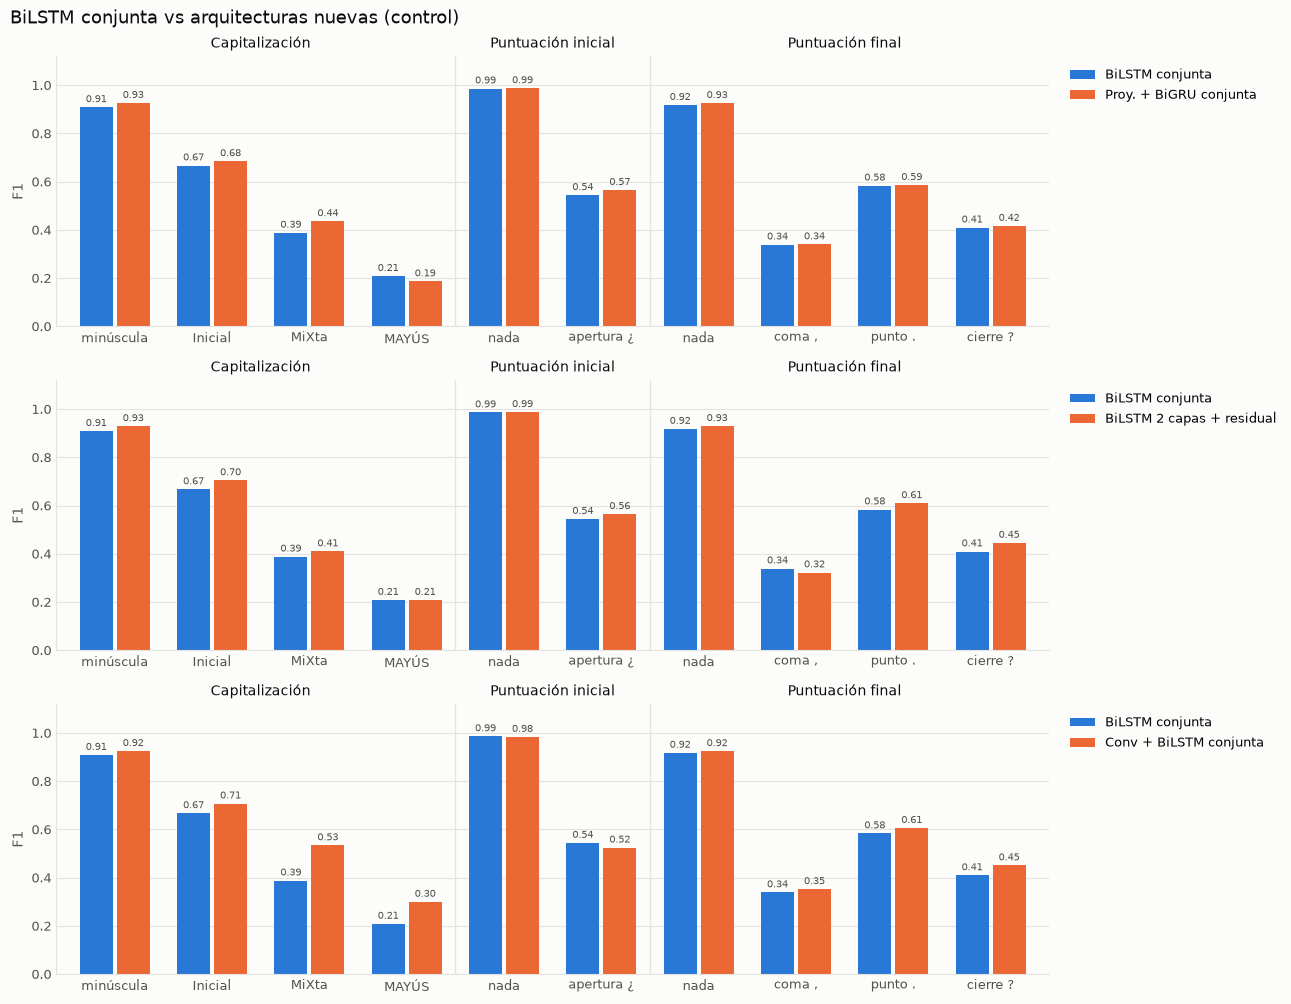

In [10]:
new_architectures = [("bidirectional_joint_lstm", "joint_projected_bigru"),
                     ("bidirectional_joint_lstm", "joint_residual_stacked_bilstm"),
                     ("bidirectional_joint_lstm", "joint_conv_bilstm")]
show_and_save(P.plot_pairs_by_class(report, SPLIT, new_architectures, "BiLSTM conjunta vs arquitecturas nuevas"),
              "7_arquitecturas_nuevas")